### 1.0 obtain diversity parameters -> homogeneity

In [4]:
import pandas as pd 
import os
import math
from collections import Counter, defaultdict
import numpy as np 


# diversity was obtained by clusters according to tree edit distance 

def diversity(labels):
    
    def entropy(labels):
        count = Counter(labels)
        total = len(labels)
        return -sum((v / total) * math.log2(v / total) for v in count.values())

  
    H = entropy(labels)
    k = len(set(labels))
    if k == 1:
        return 0.0
    if k == 0:
        return None
    return H / math.log2(k)






def process_all(dir,file_specifics):
    # current_dir = os.getcwd()
    dir = 'result_retroformer_2026_03_03_processed' + '/' + dir
    sub_dirs = [f for f in os.listdir(dir) if os.path.isdir(dir+'/'+f)]
    sub_dirs.sort()

    diversitys = []
    unique_counts = []
    search_times,success_numbs,explored_routes,solved_routes = [],[],[],[]
    # sub_files = [f for f in os.listdir(current_dir+'/'+dir) if 'iters' in f]
    for file in sub_dirs:
        for file_specific in file_specifics:
            df = pd.read_csv(dir+'/'+file+'/'+file_specific).values.flatten().tolist()
            if file_specific == '20_cluster_labels.csv':
                for i in range(len(df)):
                    try:
                        string = df[i]
                        m = string.strip("[]").split()
                        if '...' in m:
                            m.remove('...')
                        lst = list(map(int, m))
                        
                        unique_count = len(set(lst))
                        unique_counts.append(unique_count)
                        diversitys.append(diversity(lst))
                    except Exception as e:
                        print('errors:{}'.format(e))
                        print(dir+'/'+file+'/'+file_specific)
                        continue


            elif file_specific=='02_search_time.csv':
                for i in range(len(df)):
                    numbs = df[i]
                    search_times.append(numbs)
            elif file_specific=='11_is_solved.csv':
                for i in range(len(df)):
                    numbs = df[i]
                    success_numbs.append(numbs)
            elif file_specific=='09_number_of_solved_routes.csv':
                for i in range(len(df)):
                    numbs = df[i]
                    solved_routes.append(numbs)
            elif file_specific=='08_number_of_routes.csv':
                for i in range(len(df)):
                    numbs = df[i]
                    explored_routes.append(numbs)

    clean_value = [v if v is not None else 0 for v in diversitys]
    entropy_div = sum(clean_value)/1000

    clean_value = [v if v is not None else 0 for v in unique_counts]
    labels_div = sum(clean_value)/1000

    clean_value = [v if v is not None else 0 for v in success_numbs]
    success_rate =  sum(clean_value)/1000

    search_time = sum(search_times)/1000
    explored_route = sum(explored_routes)/1000
    solved_route = sum(solved_routes)/1000

    
    with open('z_process2_for_success_paths_with_diversity_result.txt', 'a+') as f:
        f.write('\n\n\n\n'+'*'*70+'\n')
        f.write(dir+'\n')
        f.write('search_time: {}\n'.format(search_time))
        f.write('success_rate: {}\n'.format(success_rate))
        f.write('explored_route: {}\n'.format(explored_route))
        f.write('solved_route: {}\n'.format(solved_route))
        f.write('labels_div: {}\n'.format(labels_div))
        f.write('entropy_div: {}\n'.format(entropy_div))
        f.write('\n\nFnished_tasks: diversitys:{},unique_counts{}:search_times:{},explored_times:{},solved_routes:{}/1000\n\n\n'.format(len(diversitys),len(unique_counts),len(search_times),len(explored_routes),len(solved_routes)))

        
        # break
dirs = ['50k_class_10','400k_class_10']
dirs = ['50k_kd_class_10']

file_specifics = ['02_search_time.csv','08_number_of_routes.csv','09_number_of_solved_routes.csv','11_is_solved.csv','20_cluster_labels.csv']

for dir in dirs:

    process_all(dir=dir,file_specifics=file_specifics)



Duplicate key in file PosixPath('/home/kara_chen/anaconda3/envs/amp/lib/python3.8/site-packages/matplotlib/mpl-data/matplotlibrc'), line 790 ('font.family:sans-serif')
Duplicate key in file PosixPath('/home/kara_chen/anaconda3/envs/amp/lib/python3.8/site-packages/matplotlib/mpl-data/matplotlibrc'), line 791 ('font.sans-serif:SimHei')
Duplicate key in file PosixPath('/home/kara_chen/anaconda3/envs/amp/lib/python3.8/site-packages/matplotlib/mpl-data/matplotlibrc'), line 792 ('axes.unicode_minus:False')


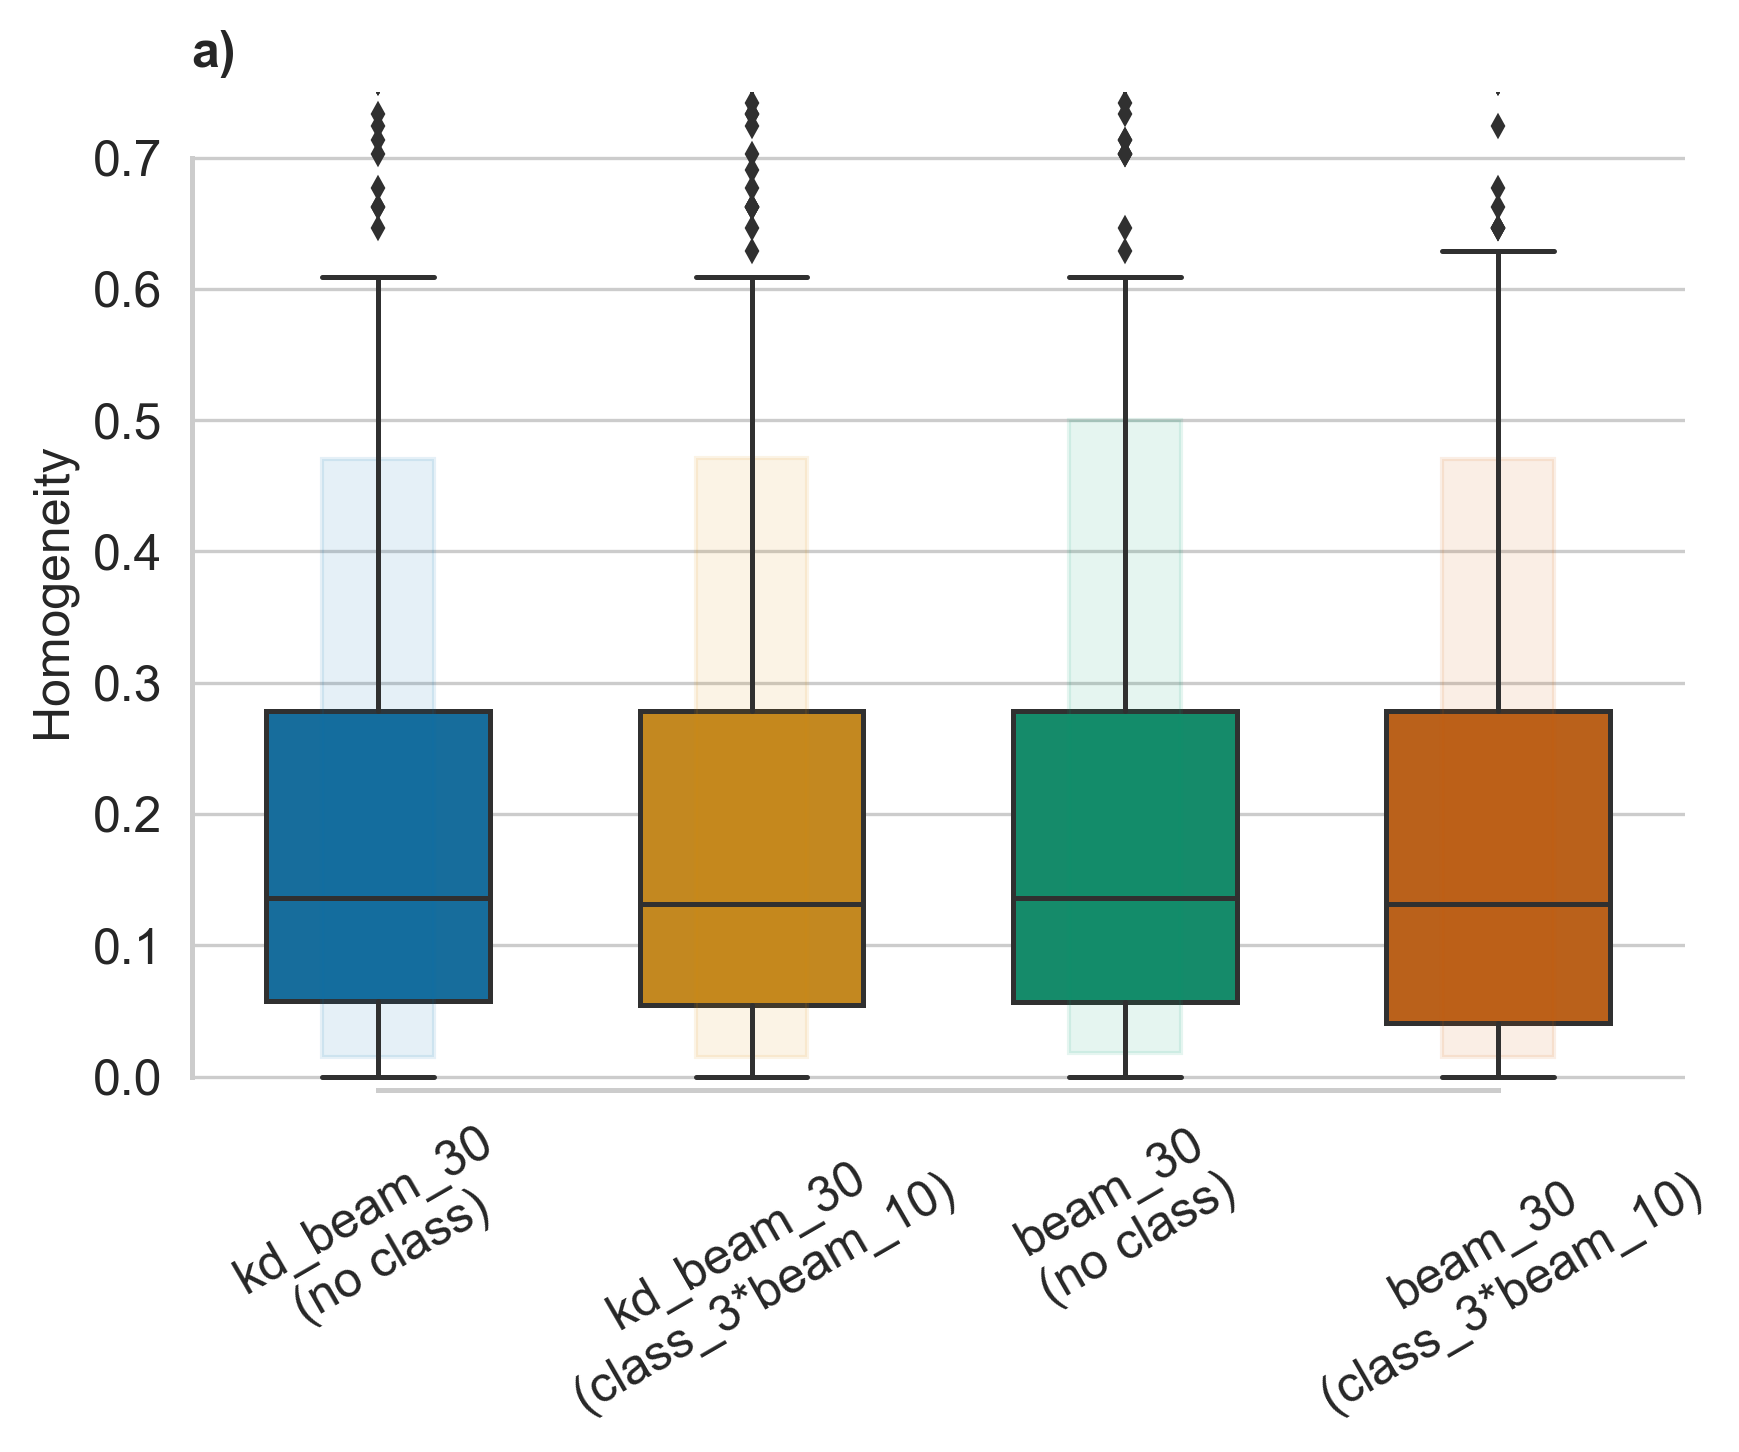

In [4]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 设置风格
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.linewidth'] = 1.2
sns.set_style("whitegrid")

# 构造 DataFrame
df = pd.DataFrame(
    [(k, v) for k, lst in result_dict.items() for v in lst],
    columns=["Types", "Homogeneity"]
)
'''
palette="Set2"         # 绿色、橙色、紫色为主，科研风格
palette="pastel"       # 低饱和度、浅色风格
palette="colorblind"   # 对色盲友好，适合科研发表
'''
# 创建图
plt.figure(figsize=(6, 5),dpi=300)  # 加宽画布以容纳长 label

# 非常重要的参数
order = ['kd_beam_30\n(no class)', 'kd_beam_30\n(class_3*beam_10)', 'beam_30\n(no class)','beam_30\n(class_3*beam_10)']

# 画图
ax = sns.boxplot(
    data=df,
    x="Types",
    y="Homogeneity",
    linewidth=1.2,
    fliersize=3,         # 控制离群点大小
    palette="colorblind",
    width=0.6,
    order=order
)


# # 添加额外10%和90%的线 （除了默认的25%和75%的线））
# 

# for i,label in enumerate(order):
#     values = result_dict[label]
#     quantiles = np.percentile(values, [10, 90])
#     for q in quantiles:
#         plt.hlines(y=q, xmin=i + 0.8, xmax=i + 1.2, color='red', linestyle='--')

# 添加额外的框
from matplotlib.patches import Rectangle
# 生成 palette 映射表
palette = sns.color_palette("colorblind", n_colors=len(order))
color_map = {label: palette[i] for i, label in enumerate(order)}

# 画小框
for idx, label in enumerate(order):
    values = result_dict[label]
    q10, q90 = np.percentile(values, [10, 90])

    rect = Rectangle(
        (idx - 0.15, q10),
        0.3,
        q90 - q10,
        linewidth=1,
        edgecolor=color_map[label],
        facecolor=color_map[label],
        alpha=0.1  # 调整透明度
    )
    ax.add_patch(rect)




# 去除 x 轴标题
ax.set_xlabel("")

# 设置 y 轴标题
ax.set_ylabel("Homogeneity", fontsize=12)

# 标题
ax.set_title("a)", loc="left", fontsize=12, fontweight='bold')

# 设置类别标签倾斜 + 加大间距
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='center')  # 倾斜显示，右对齐

# 限制 y 轴范围（可选）例如最大值为 1.05
ax.set_ylim(-0.01, 0.75)

# 去边框
sns.despine(trim=True)

# 紧凑布局防止 label 被遮挡
plt.tight_layout()
plt.show()
